VEHICLE SILHOUETTES CLASSIFICATION

DATASET INFORMATION
-----------------------------------------------------------------
Dataset Shape: (846, 19)
Missing Values: 0


,compactness,circularity,distance_circularity,radius_ratio,pr_axis_aspect_ratio,max_length_aspect_ratio,scatter_ratio,elongatedness,pr_axis_rectangularity,max_length_rectangularity,scaled_variance_major_axis,scaled_variance_minor_axis,scaled_radius_of_gyration,skewness_major_axis,skewness_minor_axis,kurtosis_minor_axis,kurtosis_major_axis,hollows_ratio,class
0,95,48,83,178,72,10,162,42,20,159,176,379,184,70,6,16,187,197,van
1,91,41,84,141,57,9,149,45,19,143,170,330,158,72,9,14,189,199,van
2,104,50,106,209,66,10,207,32,23,158,223,635,220,73,14,9,188,196,saab
3,93,41,82,159,63,9,144,46,19,143,160,309,127,63,6,10,199,207,van
4,85,44,70,205,103,52,149,45,19,144,241,325,188,127,9,11,180,183,bus



Vehicle Class Distribution:
class
bus     218
saab    217
opel    212
van     199
Name: count, dtype: int64


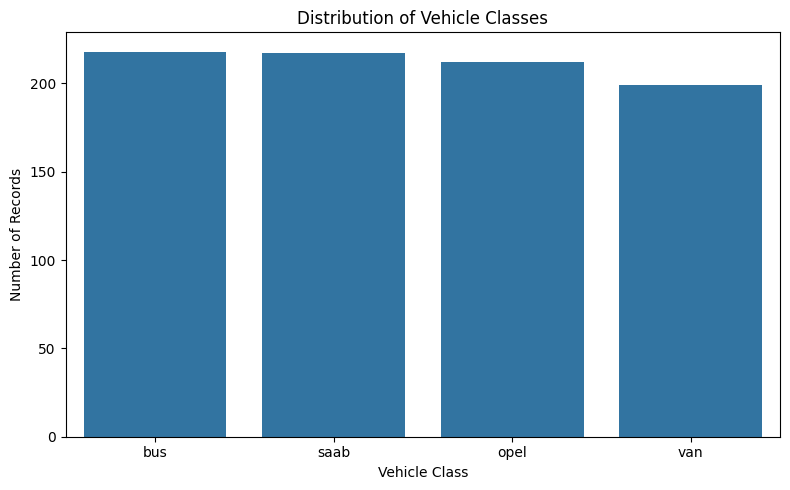

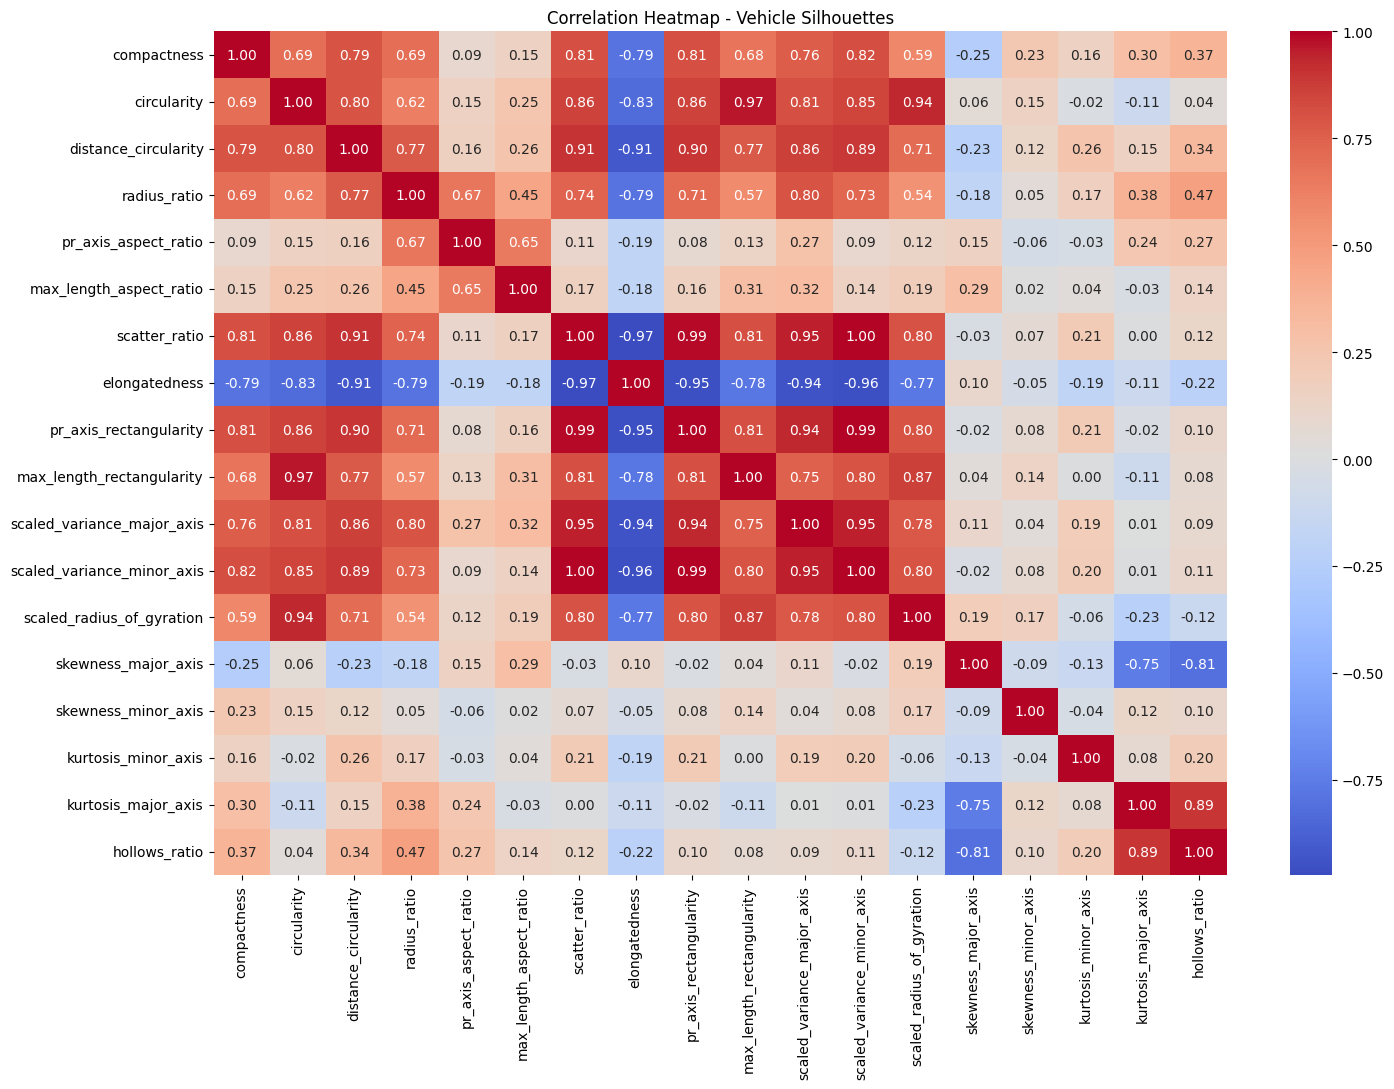

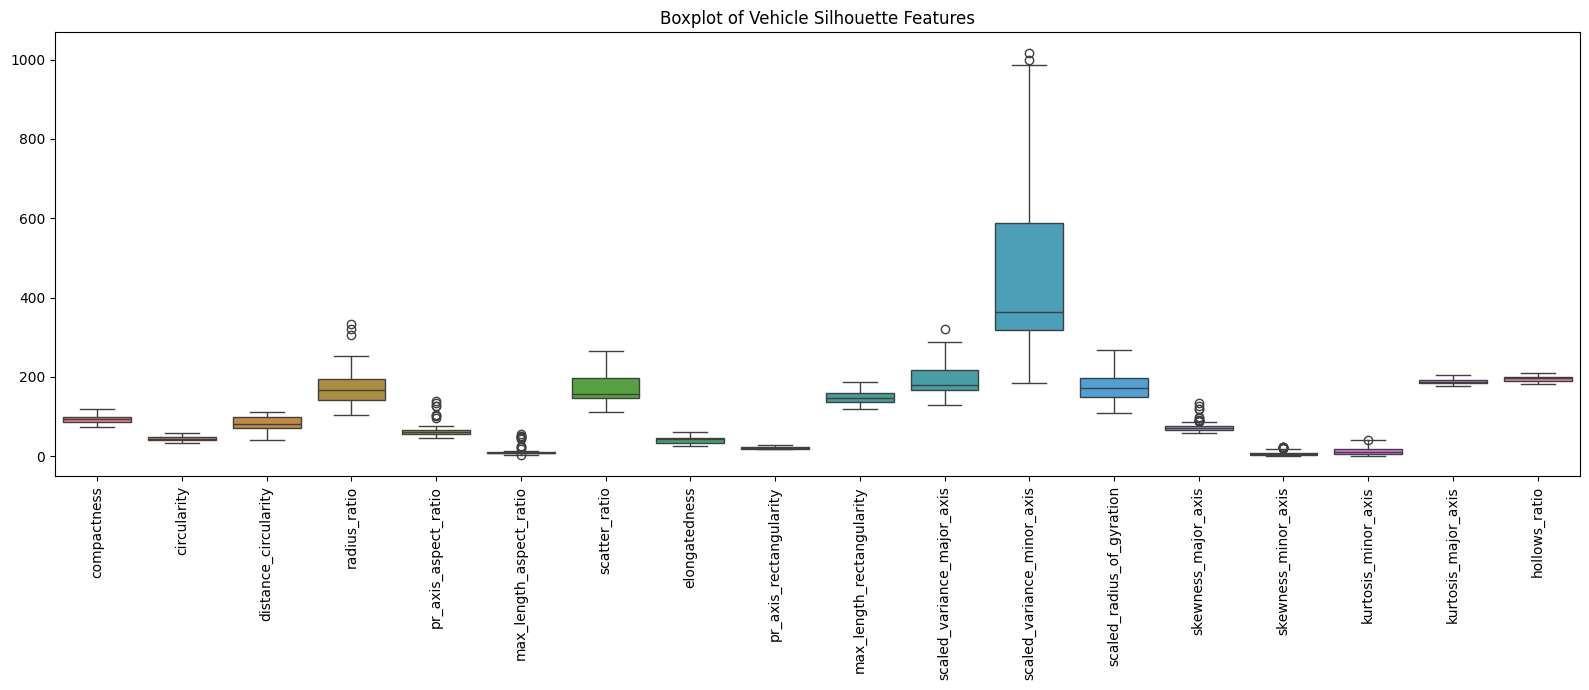


FEATURE SHAPE: (846, 18)
TARGET SHAPE: (846,)

VEHICLE CLASSES: ['bus' 'opel' 'saab' 'van']

TRAINING SAMPLES: 676
TESTING SAMPLES: 170
TRAINING FEATURE SHAPE: (676, 18)
TESTING FEATURE SHAPE: (170, 18)

MODEL TRAINING
-----------------------------------------------------------------
Logistic Regression training completed successfully.
Decision Tree training completed successfully.
KNN training completed successfully.
Naive Bayes training completed successfully.
SVM training completed successfully.

MODEL EVALUATION
-----------------------------------------------------------------
Logistic Regression evaluation completed successfully.
Decision Tree evaluation completed successfully.
KNN evaluation completed successfully.
Naive Bayes evaluation completed successfully.
SVM evaluation completed successfully.

FINAL MODEL PERFORMANCE COMPARISON


,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Model,,,,,,
Logistic Regression,0.8176,0.9504,0.8172,0.8179,0.8126,0.7599
Decision Tree,0.7176,0.8114,0.7349,0.7173,0.7229,0.6242
KNN,0.7235,0.9055,0.7297,0.7219,0.7222,0.6332
Naive Bayes,0.4353,0.7789,0.4636,0.4446,0.4087,0.2676
SVM,0.7647,0.9287,0.7646,0.7654,0.7626,0.6877



BEST MODEL: Logistic Regression
BEST ACCURACY: 0.8176


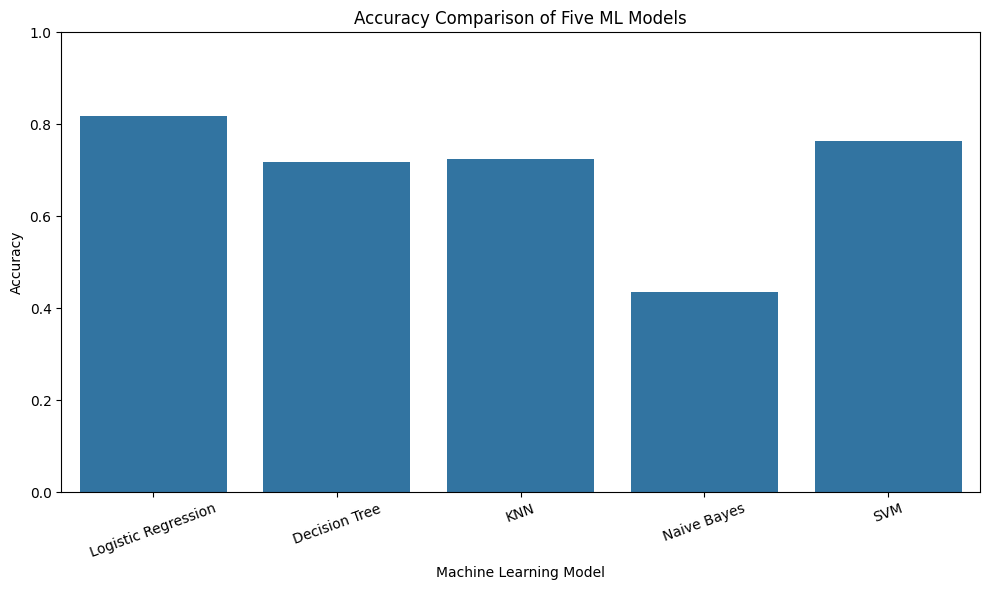

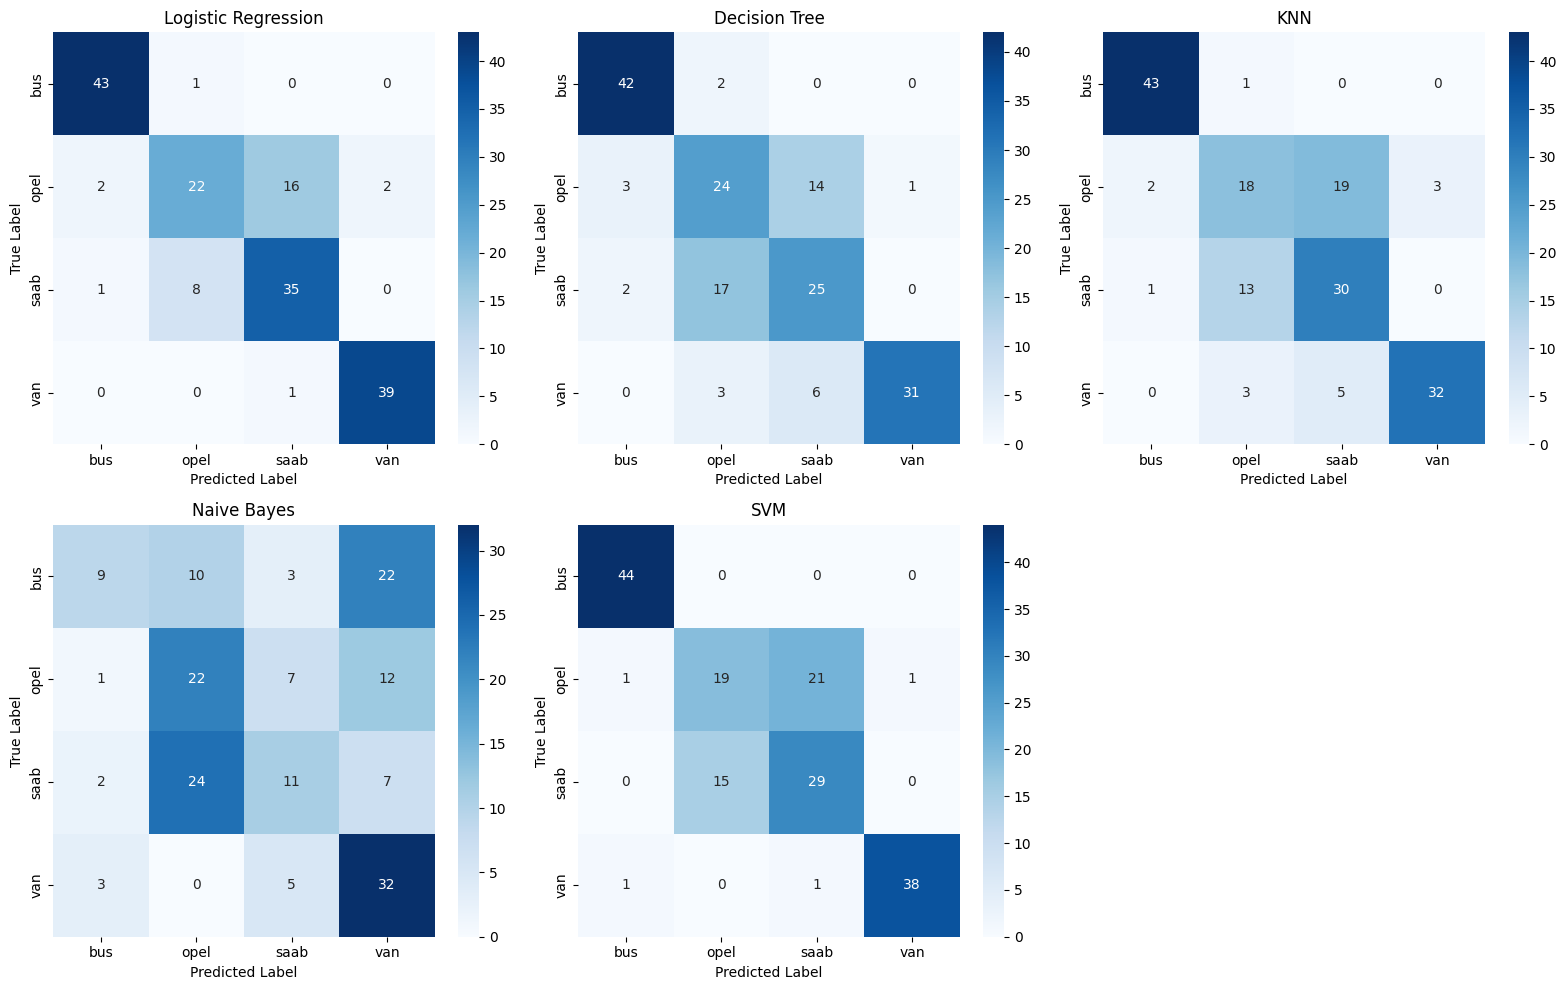


CLASSIFICATION REPORT: Logistic Regression
              precision    recall  f1-score   support

         bus       0.93      0.98      0.96        44
        opel       0.71      0.52      0.60        42
        saab       0.67      0.80      0.73        44
         van       0.95      0.97      0.96        40

    accuracy                           0.82       170
   macro avg       0.82      0.82      0.81       170
weighted avg       0.82      0.82      0.81       170


CLASSIFICATION REPORT: Decision Tree
              precision    recall  f1-score   support

         bus       0.89      0.95      0.92        44
        opel       0.52      0.57      0.55        42
        saab       0.56      0.57      0.56        44
         van       0.97      0.78      0.86        40

    accuracy                           0.72       170
   macro avg       0.73      0.72      0.72       170
weighted avg       0.73      0.72      0.72       170


CLASSIFICATION REPORT: KNN
              precis

In [5]:

# ================================================================
# MACHINE LEARNING ASSIGNMENT 2
# VEHICLE SILHOUETTES - MULTICLASS CLASSIFICATION
# ================================================================

# 1. IMPORT LIBRARIES
# ================================================================

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

# ================================================================
# 2. CONFIGURATION
# ================================================================

RANDOM_STATE = 42
TEST_SIZE = 0.20

DATA_PATH = (
    "/home/s2026aj05474/Desktop/Assignment2/vehicle_silhouettes.csv"
)

MODEL_DIR = "model"
os.makedirs(MODEL_DIR, exist_ok=True)

print("=" * 65)
print("VEHICLE SILHOUETTES CLASSIFICATION")
print("=" * 65)


# ================================================================
# 3. LOAD DATASET
# ================================================================

df = pd.read_csv(DATA_PATH)

print("\nDATASET INFORMATION")
print("-" * 65)

print("Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())

if df.isnull().sum().sum() > 0:
    raise ValueError("Dataset contains missing values.")

if "class" not in df.columns:
    raise ValueError("Target column 'class' is missing.")

display(df.head())

print("\nVehicle Class Distribution:")
print(df["class"].value_counts())


# ================================================================
# 4. EXPLORATORY DATA ANALYSIS
# ================================================================

# Class distribution

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="class",
    order=df["class"].value_counts().index
)

plt.title("Distribution of Vehicle Classes")
plt.xlabel("Vehicle Class")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


# Correlation heatmap

plt.figure(figsize=(15, 11))

sns.heatmap(
    df.drop(columns=["class"]).corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap - Vehicle Silhouettes")
plt.tight_layout()
plt.show()


# Boxplot

plt.figure(figsize=(16, 7))

sns.boxplot(data=df.drop(columns=["class"]))

plt.title("Boxplot of Vehicle Silhouette Features")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


# ================================================================
# 5. FEATURE AND TARGET SEPARATION
# ================================================================

X = df.drop(columns=["class"])
y = df["class"]

print("\nFEATURE SHAPE:", X.shape)
print("TARGET SHAPE:", y.shape)


# ================================================================
# 6. LABEL ENCODING
# ================================================================

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

class_names = label_encoder.classes_

print("\nVEHICLE CLASSES:", class_names)


# ================================================================
# 7. TRAIN-TEST SPLIT
# ================================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_encoded
)

print("\nTRAINING SAMPLES:", len(X_train))
print("TESTING SAMPLES:", len(X_test))

print("TRAINING FEATURE SHAPE:", X_train.shape)
print("TESTING FEATURE SHAPE:", X_test.shape)


# ================================================================
# 8. DEFINE CLASSIFICATION MODELS
# ================================================================

models = {

    "Logistic Regression": LogisticRegression(
        max_iter=2000
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Naive Bayes": GaussianNB(),

    "SVM": SVC(
        probability=True,
        random_state=RANDOM_STATE
    )
}


# ================================================================
# 9. PREPROCESSING AND MODEL TRAINING
# ================================================================

trained_models = {}

print("\nMODEL TRAINING")
print("-" * 65)

for name, classifier in models.items():

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(name, "training completed successfully.")


# ================================================================
# 10. MODEL EVALUATION
# ================================================================

results = {}
predictions = {}

print("\nMODEL EVALUATION")
print("-" * 65)

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    y_prob = model.predict_proba(X_test)

    predictions[name] = y_pred

    results[name] = {

        "Accuracy": accuracy_score(
            y_test, y_pred
        ),

        "AUC": roc_auc_score(
            y_test,
            y_prob,
            multi_class="ovr",
            average="macro"
        ),

        "Precision": precision_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Recall": recall_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "F1 Score": f1_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "MCC": matthews_corrcoef(
            y_test, y_pred
        )
    }

    print(name, "evaluation completed successfully.")


# ================================================================
# 11. MODEL COMPARISON TABLE
# ================================================================

results_df = pd.DataFrame(results).T

results_df.index.name = "Model"

print("\nFINAL MODEL PERFORMANCE COMPARISON")
print("=" * 65)

display(results_df.round(4))

best_model_name = results_df["Accuracy"].idxmax()

print("\nBEST MODEL:", best_model_name)

print(
    "BEST ACCURACY:",
    round(results_df.loc[best_model_name, "Accuracy"], 4)
)


# ================================================================
# 12. ACCURACY COMPARISON CHART
# ================================================================

plt.figure(figsize=(10, 6))

sns.barplot(
    x=results_df.index,
    y=results_df["Accuracy"]
)

plt.title("Accuracy Comparison of Five ML Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")

plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


# ================================================================
# 13. CONFUSION MATRICES
# ================================================================

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes = axes.flatten()

for i, (name, y_pred) in enumerate(predictions.items()):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=np.arange(len(class_names))
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=axes[i]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("True Label")

fig.delaxes(axes[5])

plt.tight_layout()
plt.show()


# ================================================================
# 14. CLASSIFICATION REPORTS
# ================================================================

for name, y_pred in predictions.items():

    print("\n" + "=" * 65)
    print("CLASSIFICATION REPORT:", name)
    print("=" * 65)

    print(
        classification_report(
            y_test,
            y_pred,
            labels=np.arange(len(class_names)),
            target_names=class_names,
            zero_division=0
        )
    )


# ================================================================
# 15. SAVE TRAINED MODELS
# ================================================================

print("\nSAVING TRAINED MODELS")
print("-" * 65)

for name, model in trained_models.items():

    filename = name.lower().replace(" ", "_") + ".pkl"

    filepath = os.path.join(MODEL_DIR, filename)

    joblib.dump(model, filepath)

    print(name, "saved successfully.")


# Save label encoder

joblib.dump(
    label_encoder,
    os.path.join(MODEL_DIR, "label_encoder.pkl")
)

print("Label encoder saved successfully.")


# ================================================================
# 16. EXPORT TEST DATA
# ================================================================

test_data = X_test.copy()

test_data["class"] = label_encoder.inverse_transform(y_test)

test_data.to_csv(
    "test_data.csv",
    index=False
)

print("Test dataset saved:", test_data.shape)


# ================================================================
# 17. EXPORT MODEL COMPARISON
# ================================================================

results_df.to_csv("model_comparison.csv")

print("Model comparison saved successfully.")


# ================================================================
# 18. EXPORT MODEL PREDICTIONS
# ================================================================

prediction_df = pd.DataFrame({

    "Actual Class": label_encoder.inverse_transform(y_test)

})

for name, y_pred in predictions.items():

    prediction_df[name] = label_encoder.inverse_transform(y_pred)

prediction_df.to_csv(
    "model_predictions.csv",
    index=False
)

print("Model predictions saved successfully.")


# ================================================================
# 19. FINAL SUMMARY
# ================================================================

print("\n" + "=" * 65)
print("ASSIGNMENT EXECUTION COMPLETED")
print("=" * 65)

print("Dataset Records:", len(df))
print("Input Features:", X.shape[1])
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("Number of Models:", len(trained_models))

print("\nBest Performing Model:", best_model_name)

print(
    "Best Accuracy:",
    f"{results_df.loc[best_model_name, 'Accuracy']:.4f}"
)

print("\nGenerated Files:")
print("- model/ (five models and label encoder)")
print("- test_data.csv")
print("- model_comparison.csv")
print("- model_predictions.csv")

print("\nALL TASKS COMPLETED SUCCESSFULLY!")
print("=" * 65)


In [11]:
%pip install -r requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 103.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 797.2/797.2 kB 52.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 143.5 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 107.1 MB/s eta 0:00:00
  Attempting uninstall: typing-extensions
    Found existing installation: typing_extensions 4.11.0
    Uninstalling typing_extensions-4.11.0:
      Successfully uninstalled typing_extensions-4.11.0
  Attempting uninstall: protobuf
    Found existing installation: protobuf 4.25.3
    Uninstalling protobuf-4.25.3:
      Successfully uninstalled protobuf-4.25.3
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow 2.17.0 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<5.0.0dev,>=3.20.3, but you have protobuf 7.